# 02 — Causal Feature Engineering, Model Benchmark & Error Analysis

Compares Seasonal Naive (`t-168h`), ARIMA, Prophet, and LightGBM on a chronological 8,760-hour (365-day) holdout window using strictly causal features for 24h-ahead forecasting.

In [1]:
from pathlib import Path
import urllib.request

# Colab-friendly setup: ensures src modules and PJME CSV are available
if not Path('src/data.py').exists():
    import subprocess
    subprocess.run(['git', 'clone', 'https://github.com/GaneshArwan/time_series_energy_demand.git', 'repo'], check=True)
    import os
    os.chdir('repo')

data_path = Path('data/PJME_hourly.csv')
if not data_path.exists():
    data_path.parent.mkdir(parents=True, exist_ok=True)
    url = 'https://raw.githubusercontent.com/panambY/Hourly_Energy_Consumption/refs/heads/master/data/PJME_hourly.csv'
    urllib.request.urlretrieve(url, data_path)
print(f'Dataset ready: {data_path} ({data_path.stat().st_size:,} bytes)')

Dataset ready: data\PJME_hourly.csv (4,070,265 bytes)


In [2]:
import json
import matplotlib.pyplot as plt
import pandas as pd
from src.data import load_pjm_series
from src.features import build_causal_features

df, _ = load_pjm_series('PJME_hourly.csv')
featured, feature_cols = build_causal_features(df, horizon_hours=24)
print(f'Featured rows: {len(featured):,}, feature count: {len(feature_cols)}')
print('Features:', feature_cols)

Featured rows: 145,056, feature count: 17
Features: ['hour', 'dayofweek', 'month', 'dayofyear', 'is_weekend', 'hour_sin', 'hour_cos', 'doy_sin', 'doy_cos', 'lag_24', 'lag_48', 'lag_168', 'lag_336', 'roll_mean_24', 'roll_std_24', 'roll_mean_168', 'roll_std_168']


In [3]:
metrics = json.loads(open('artifacts/metrics.json', encoding='utf-8').read())
errors = json.loads(open('artifacts/error_analysis.json', encoding='utf-8').read())
feat_imp = json.loads(open('artifacts/feature_importance.json', encoding='utf-8').read())

bench_df = pd.DataFrame([
    {'Model': k, 'MAE (MW)': v['mae'], 'RMSE (MW)': v['rmse'], 'MAPE (%)': v['mape']}
    for k, v in metrics['models'].items()
]).sort_values('MAE (MW)')
display(bench_df)
print('LightGBM 5-fold CV mean:', metrics['lightgbm_cv']['mean'])

,Model,MAE (MW),RMSE (MW),MAPE (%)
3,LightGBM,1881.49,2558.01,5.91
2,Prophet,3241.42,4227.92,10.23
0,Seasonal Naive (t-168h),3581.81,4852.33,11.22
1,ARIMA,5680.02,6645.42,19.59


LightGBM 5-fold CV mean: {'mae': 1658.78, 'rmse': 2331.0, 'mape': 5.02}


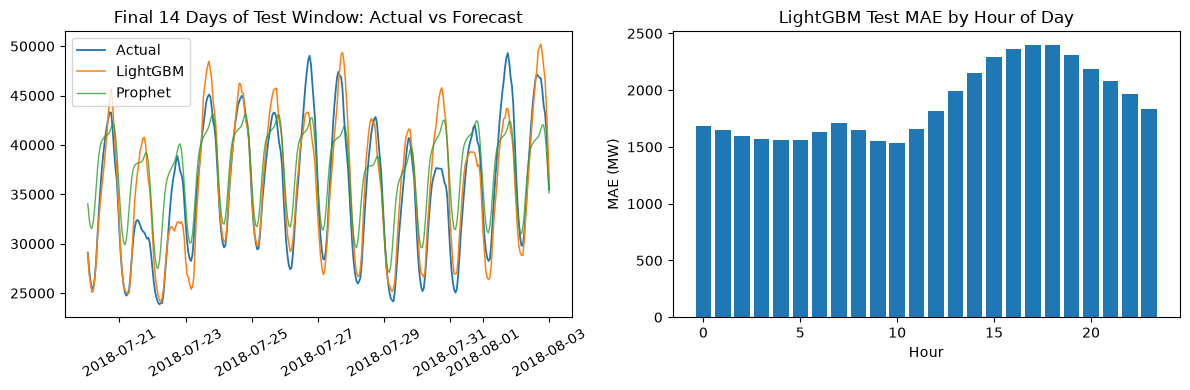

,feature,importance,importance_pct
0,roll_mean_168,3395,13.69
1,dayofyear,2621,10.57
2,roll_std_168,2585,10.42
3,roll_mean_24,2432,9.81
4,doy_sin,2231,9.00
5,dayofweek,2143,8.64
6,doy_cos,2001,8.07
7,roll_std_24,1465,5.91
8,lag_24,1452,5.85
9,lag_336,1154,4.65


,date,mae,mape,actual_mean_mw,pred_mean_mw
0,2017-12-31,6733.72,17.15,39016.00,32282.28
1,2018-06-03,5828.88,22.02,26070.29,31899.17
2,2018-07-07,5383.62,19.06,28926.50,34310.12
3,2018-05-28,5194.87,20.88,25457.46,30652.33
4,2017-09-06,5133.42,16.57,29903.00,34112.88


In [4]:
preds = pd.read_csv('artifacts/test_predictions.csv', parse_dates=['ds'])
sample = preds.tail(14 * 24)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), dpi=100)
axes[0].plot(sample['ds'], sample['actual_mw'], label='Actual', linewidth=1.3)
axes[0].plot(sample['ds'], sample['lgbm_mw'], label='LightGBM', linewidth=1.1)
axes[0].plot(sample['ds'], sample['prophet_mw'], label='Prophet', linewidth=1.0, alpha=0.8)
axes[0].set_title('Final 14 Days of Test Window: Actual vs Forecast')
axes[0].legend()
axes[0].tick_params(axis='x', rotation=30)

hr_df = pd.DataFrame(errors['by_hour'])
axes[1].bar(hr_df['hour'], hr_df['mae'])
axes[1].set_title('LightGBM Test MAE by Hour of Day')
axes[1].set_xlabel('Hour')
axes[1].set_ylabel('MAE (MW)')
plt.tight_layout()
plt.show()

imp_df = pd.DataFrame(feat_imp['features']).head(10)
display(imp_df)
display(pd.DataFrame(errors['top_10_highest_mae_days']).head(5))